# **05 · Líneas base**

Este notebook mide dos métodos sin red neuronal. Son el punto de comparación de todas las iteraciones: una red solo aporta valor si les gana.

## **0. Objetivo**

- **Igual que la semana pasada (naive estacional):** cada día a predecir copia lo vendido el mismo día de la semana anterior. Es lo que haría alguien "a ojo".
- **Promedio de los mismos días:** cada día a predecir es el promedio de los mismos días de la semana que hay en la ventana de entrada (2 con 14 días, 4 con 28). Usa la misma información que las redes, así que la comparación es justa.

El promedio móvil simple se descartó porque ignora el patrón semanal (entre semana se vende menos y el fin de semana más), que el análisis exploratorio mostró como el más fuerte.

## **1. Carga y ventanas**

Las ventanas se arman con `src/windows.py`, el mismo código que usarán las redes. Para que las ventanas de 14 y 28 días se comparen sobre los mismos días, ambas empiezan a predecir desde el día 28 de cada serie (`first_offset=28`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.baselines import same_weekday_mean, seasonal_naive
from src.metrics import evaluate
from src.windows import make_windows

df = pd.read_parquet(ROOT / "data" / "processed" / "unified.parquet")
EVAL_SPLITS = ["val", "test", "test_season"]

windows = {lookback: make_windows(df, lookback, EVAL_SPLITS, first_offset=28) for lookback in (14, 28)}
for lookback, w in windows.items():
    print(f"Ventana de {lookback} días: {len(w):,} ejemplos")

Ventana de 14 días: 32,910 ejemplos
Ventana de 28 días: 32,910 ejemplos


## **2. Cómo predice cada línea base**

Un ejemplo con la baguette tradicional de French Bakery en validación: los 7 días predichos por cada línea base contra lo que realmente se vendió. Si algún día el local hubiera cerrado, su venta real aparecería vacía y no contaría para el error.

In [2]:
w = windows[28]
example = w.meta.index[(w.meta["product_id"] == "french_bakery_traditional_baguette") & (w.meta["split"] == "val")][0]
days = pd.date_range(w.meta.loc[example, "first_date"], periods=7)
scale = w.scale[example]

pd.DataFrame({
    "día": days.strftime("%a %d-%m"),
    "venta real": (w.target[example] * scale).round(0),
    "igual que la semana pasada": (seasonal_naive(w)[example] * scale).round(0),
    "promedio de los mismos días": (same_weekday_mean(w)[example] * scale).round(0),
}).assign(**{"venta real": lambda t: t["venta real"].where(w.mask[example] == 1)})

,día,venta real,igual que la semana pasada,promedio de los mismos días
0,Fri 01-04,79.0,82.0,94.0
1,Sat 02-04,107.0,166.0,148.0
2,Sun 03-04,189.0,166.0,205.0
3,Mon 04-04,93.0,113.0,109.0
4,Tue 05-04,82.0,100.0,83.0
5,Wed 06-04,70.0,68.0,63.0
6,Thu 07-04,87.0,82.0,72.0


## **3. Métricas**

Todas se calculan en unidades reales y solo en días con el local abierto:

- **MAE:** por cuántas unidades se equivoca, en promedio, por día.
- **RMSE:** como el MAE, pero castiga más los errores grandes; sirve para ver si un método falla poco seguido pero muy feo.
- **WAPE:** el error como porcentaje de lo vendido. Es la métrica principal para comparar iteraciones porque no depende de la escala de cada negocio.
- **MAE relativo:** el MAE dividido entre el de "igual que la semana pasada" sobre los mismos días. Menos de 1 significa que mejora a esa línea base.

Cada fila cuenta predicciones: un mismo día aparece en hasta 7 ejemplos, porque se predice desde 1 hasta 7 días antes.

## **4. Resultados**

In [3]:
results = []
for lookback, w in windows.items():
    naive = seasonal_naive(w)
    for name, prediction in [("Igual que la semana pasada", naive), ("Promedio de los mismos días", same_weekday_mean(w))]:
        table = evaluate(w, prediction, naive).reset_index()
        results.append(table.assign(modelo=name, ventana=lookback))
results = pd.concat(results, ignore_index=True)

results[(results["ventana"] == 28)].set_index(["modelo", "split", "dataset"]).drop(columns="ventana").round(3)

predicciones     MAE  \
modelo                      split       dataset                               
Igual que la semana pasada  test        bread_basket          16862   2.684   
                                        ddop                 104475  25.828   
                            test_season french_bakery         25846   6.071   
                            val         ddop                  48279  22.116   
                                        french_bakery         26824   5.169   
                            Total                            222286  18.476   
Promedio de los mismos días test        bread_basket          16862   2.370   
                                        ddop                 104475  21.189   
                            test_season french_bakery         25846   7.449   
                            val         ddop                  48279  17.771   
                                        french_bakery         26824   4.208   
                            Total                            222286  15.373   

                                                         RMSE   WAPE  \
modelo                      split       dataset                        
Igual que la semana pasada  test        bread_basket    4.190  0.479   
                                        ddop           47.067  0.218   
                            test_season french_bakery  17.534  0.346   
                            val         ddop           40.606  0.252   
                                        french_bakery  17.624  0.489   
                            Total                      38.391  0.235   
Promedio de los mismos días test        bread_basket    3.625  0.423   
                                        ddop           38.566  0.178   
                            test_season french_bakery  24.512  0.424   
                            val         ddop           32.955  0.203   
                                        french_bakery  13.973  0.398   
                            Total                      32.083  0.196   

                                                       MAE relativo  
modelo                      split       dataset                      
Igual que la semana pasada  test        bread_basket          1.000  
                                        ddop                  1.000  
                            test_season french_bakery         1.000  
                            val         ddop                  1.000  
                                        french_bakery         1.000  
                            Total                             1.000  
Promedio de los mismos días test        bread_basket          0.883  
                                        ddop                  0.820  
                            test_season french_bakery         1.227  
                            val         ddop                  0.804  
                                        french_bakery         0.814  
                            Total                             0.832

In [4]:
results[(results["ventana"] == 14)].set_index(["modelo", "split", "dataset"]).drop(columns="ventana").round(3)

predicciones     MAE  \
modelo                      split       dataset                               
Igual que la semana pasada  test        bread_basket          16862   2.665   
                                        ddop                 104475  25.879   
                            test_season french_bakery         25846   6.071   
                            val         ddop                  48279  22.117   
                                        french_bakery         26824   5.169   
                            Total                            222286  18.498   
Promedio de los mismos días test        bread_basket          16862   2.434   
                                        ddop                 104475  23.009   
                            test_season french_bakery         25846   6.310   
                            val         ddop                  48279  19.313   
                                        french_bakery         26824   4.575   
                            Total                            222286  16.479   

                                                         RMSE   WAPE  \
modelo                      split       dataset                        
Igual que la semana pasada  test        bread_basket    4.164  0.476   
                                        ddop           47.140  0.218   
                            test_season french_bakery  17.534  0.346   
                            val         ddop           40.607  0.252   
                                        french_bakery  17.624  0.489   
                            Total                      38.433  0.235   
Promedio de los mismos días test        bread_basket    3.743  0.435   
                                        ddop           42.004  0.194   
                            test_season french_bakery  20.235  0.360   
                            val         ddop           35.326  0.220   
                                        french_bakery  15.454  0.433   
                            Total                      34.319  0.210   

                                                       MAE relativo  
modelo                      split       dataset                      
Igual que la semana pasada  test        bread_basket          1.000  
                                        ddop                  1.000  
                            test_season french_bakery         1.000  
                            val         ddop                  1.000  
                                        french_bakery         1.000  
                            Total                             1.000  
Promedio de los mismos días test        bread_basket          0.913  
                                        ddop                  0.889  
                            test_season french_bakery         1.039  
                            val         ddop                  0.873  
                                        french_bakery         0.885  
                            Total                             0.891

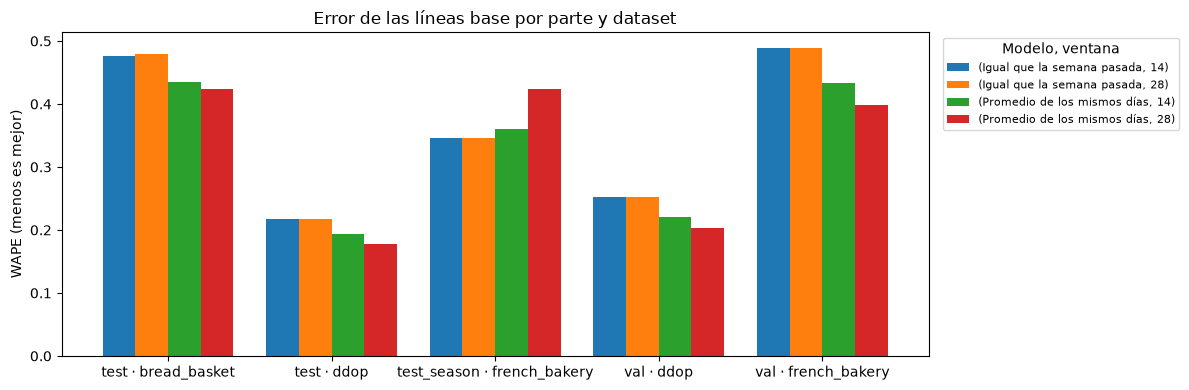

In [5]:
groups = results[results["split"] != "Total"].assign(grupo=lambda t: t["split"] + " · " + t["dataset"])
pivot = groups.pivot_table(index="grupo", columns=["modelo", "ventana"], values="WAPE")

ax = pivot.plot.bar(figsize=(12, 4), width=0.8)
ax.set_ylabel("WAPE (menos es mejor)")
ax.set_xlabel("")
ax.set_title("Error de las líneas base por parte y dataset")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Modelo, ventana", fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

## **5. Conclusiones**

- **El promedio de los mismos días es la línea base a vencer.** Con 28 días mejora entre 12 y 20 % a "igual que la semana pasada" en validación y en la prueba principal, porque promediar varias semanas suaviza los días atípicos.
- **En The Bread Basket**, la mejor línea base se equivoca por 2.4 unidades por día, un 42 % de lo vendido. Es el error que la red tiene que reducir en el negocio de la demostración.
- **El cambio de temporada confirma la limitación esperada.** En la prueba de temporada (julio a septiembre de French Bakery), promediar las últimas 4 semanas es 23 % peor que copiar la semana anterior, porque esas semanas todavía son de nivel bajo; con 14 días la pérdida es mucho menor. Es una primera evidencia para la iteración que compara ventanas de 14 y 28 días.

## **6. Guardar resultados**

Los resultados se guardan en `results/` como la iteración 0 de la tabla de iteraciones.

In [6]:
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
results.assign(iteracion=0).to_csv(RESULTS / "00_lineas_base.csv", index=False)
print(f"Guardado en {(RESULTS / '00_lineas_base.csv').relative_to(ROOT)}")

Guardado en results/00_lineas_base.csv
